In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
image_path = 'computers.jpg'
img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]
img.shape

(480, 640, 3)

In [3]:
sift = cv2.SIFT_create()
bf = cv2.BFMatcher()


def locate(ref, scene, ratio=0.75):
    k1, d1 = sift.detectAndCompute(ref, None)
    k2, d2 = sift.detectAndCompute(scene, None)
    pairs = bf.knnMatch(d1, d2, k=2)
    good = [m for m, n in pairs if m.distance < ratio * n.distance]
    if len(good) < 4:
        return None, len(good), 0
    src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    if H is None:
        return None, len(good), 0
    h, w = ref.shape[:2]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    return cv2.perspectiveTransform(corners, H), len(good), int(mask.sum())

In [4]:
assets = {
    'Front computer': (305, 290, 495, 480),
    'Second row monitor': (185, 225, 285, 300),
}
refs = {name: img[y1:y2, x1:x2] for name, (x1, y1, x2, y2) in assets.items()}

src_pts = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
dst_pts = np.float32([[60, 40], [w - 30, 80], [w - 70, h - 40], [20, h - 90]])
P = cv2.getPerspectiveTransform(src_pts, dst_pts)
scene = cv2.warpPerspective(img, P, (w, h), borderValue=(128, 128, 128))
scene = cv2.convertScaleAbs(scene, alpha=0.85, beta=20)

In [5]:
result = scene.copy()
for name, ref in refs.items():
    box, good, inliers = locate(ref, result)
    print(f'{name} - good matches:', good, 'inliers:', inliers)
    if box is not None:
        cv2.polylines(result, [np.int32(box)], True, (0, 255, 0), 3)
        x, y = np.int32(box[0, 0])
        cv2.putText(result, name, (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)

Front computer - good matches: 25 inliers: 25


Second row monitor - good matches: 5 inliers: 4


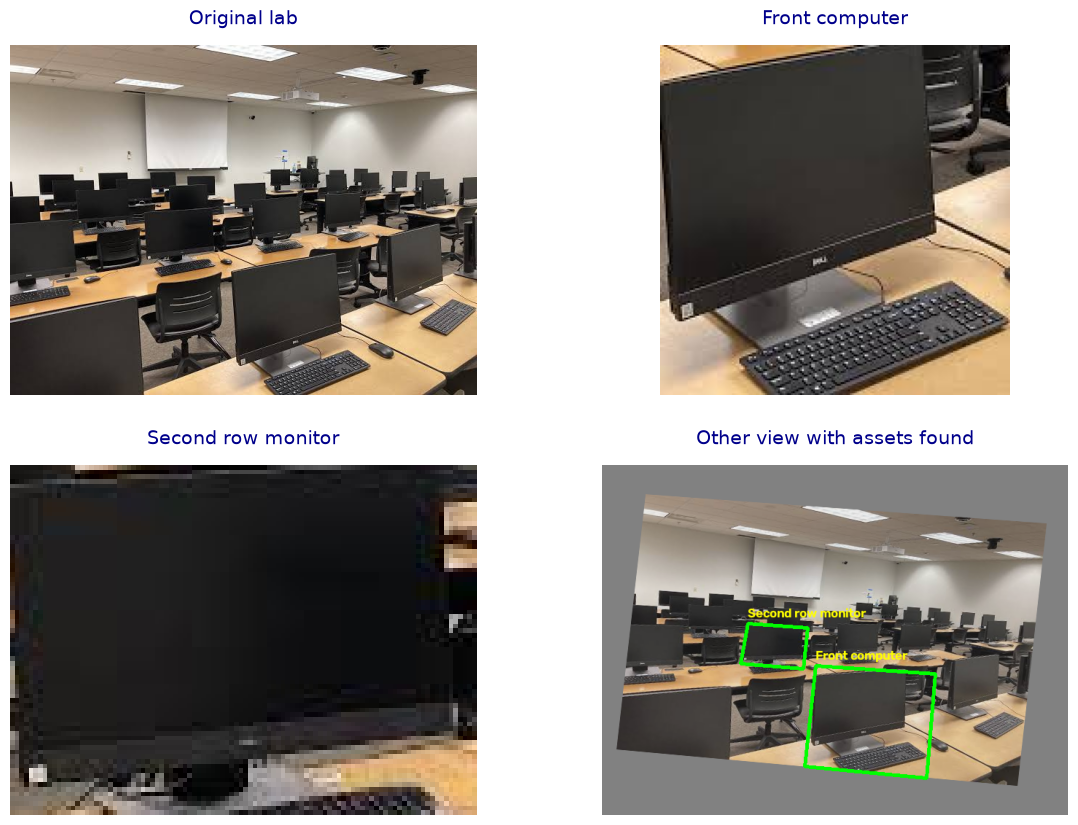

In [6]:
panels = [('Original lab', img), ('Front computer', refs['Front computer']), ('Second row monitor', refs['Second row monitor']), ('Other view with assets found', result)]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (title, im) in zip(axes, panels):
    ax.imshow(im)
    ax.axis('off')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

plt.show()

In [7]:
os.makedirs('output', exist_ok=True)
cv2.imwrite('output/task2_assets.png', cv2.cvtColor(result, cv2.COLOR_RGB2BGR))

True

Two assets are cropped as references, the front computer with its keyboard and a monitor in the second row. Their SIFT features are matched against the lab view with the ratio test (0.75) and a RANSAC homography, and the projected corners give the box.

Front computer: 25 good matches, 25 inliers. Second row monitor: 5 good matches, 4 inliers. It lands on the right monitor but the match is weak since a plain black screen has few keypoints. Assets with text and detail like the Dell logo and the keyboard work better.